# 1. Transformer가 등장하기까지
RNN의 순차 처리 > Seq2Seq > 긴 문장의 정보 병목 > Attention > Transformer

# 2. Seq2Seq (Sequence-to-Sequence)
- 시퀀스투시퀀스(Sequence-to-Sequence, Seq2Seq) 모델은 입력 시퀀스를 받아 출력 시퀀스를 생성하는 신경망 아키텍처로, 
- 주로 자연어 처리 분야에서 번역, 요약, 질의응답 등에 활용됩니다. 
- Seq2Seq 모델은 일반적으로 인코더(Encoder)와 디코더(Decoder) 두 부분으로 구성되며, 
    - 인코더는 입력 문장을 고정된 크기의 컨텍스트 벡터로 변환하고, 
    - 디코더는 이를 기반으로 출력 문장을 생성합니다. 
- RNN, LSTM, GRU 등의 순환 신경망을 활용하며, 
- 최근에는 어텐션 메커니즘과 트랜스포머 모델이 도입되어 더 긴 문맥을 효과적으로 처리할 수 있게 되었습니다. 
- [논문](https://arxiv.org/abs/1409.3215)

### Seq2Seq의 핵심
- 하나의 시퀀스를 입력받아 다른 시퀀스를 출력하는 구조
- 예) 영어 문장 > Encoder > 문장 정보 > Decoder > 한국어 문장
- 주로 RNN(LSTM, GRU)를 사용하며 두 부분으로 구성
    - Encoder: 입력 토큰을 순서대로 읽으면서 hidden state를 계속 갱신하고 입력 문장의 정보를 압축
    - Decoder: 
        - Encoder에서 전달받은 정보를 이용하여 출력 토큰을 한 개씩 생성
        - \<BOS\>같은 시작 토큰에서 출발하여 이전 토큰을 이용해 다음 토큰을 예측하고, \<EOS\>가 나오면 생성을 끝냄
        - 이전 출력이 다음 출력에 영향을 주는 생성 방식을 Auto-Regressive 방식이라고 함.

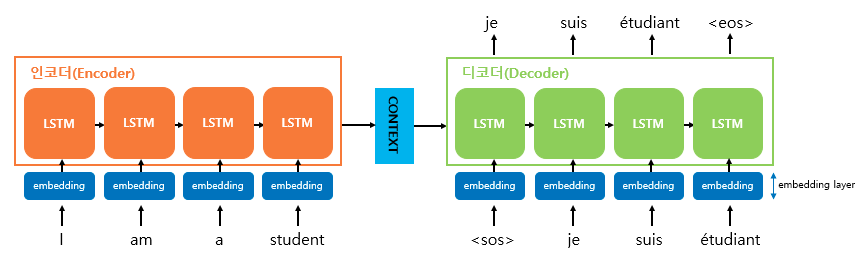

### Seq2Seq의 가장 중요한 문제
- 고전적인 RNN Seq2Seq에서는 Encoder의 마지막 hidden state 하나에 입력 문장의 정보를 압축하는 방식이 사용됨
- 문장이 길어질수록 하나의 고정된 벡터가 모든 정보를 기억해야 하므로 정보 병목(Bottleneck)현상이 일어날 수 있음
- RNN은 기본적으로 이전 시점의 계산 결과가 다음 시점에 필요함 > 긴 시퀀스의 관계를 학습하기 어렵고, 학습 시 병렬 처리도 불리

# 3. Attention Mechanism (어텐션 메커니즘)
- 기존의 RNN(Recurrent Neural Network)이나 LSTM(Long Short-Term Memory) 모델은 입력 데이터를 순차적으로 처리하기 때문에 긴 문장에서 중요한 정보를 잃어버리거나, 멀리 떨어진 단어 간의 관계를 잘 파악하지 못하는 문제가 있었습니다. 
- 어텐션은 입력 문장의 모든 단어를 한 번에 보고, 어떤 단어가 중요한지 가중치를 계산하여 집중하는 방법입니다.
- 예) "나는 오늘 학교에서 수학 시험을 봤다."라는 문장에서 "시험"이라는 단어가 가장 중요한 의미를 가진다고 가정합시다. 
    - 어텐션은 이 문장을 처리할 때 "시험"에 더 높은 가중치를 주고, 덜 중요한 단어에는 낮은 가중치를 주는 방식으로 학습합니다.

### Embedding & Context
- 토큰은 먼저 Embedding을 통해 숫자 벡터로 바뀜
- 같은 단어라도 문맥에 따라 의미가 달라질 수 있음
- Self-Attention은 주변 토큰들과의 관계를 이용하여 기존 임베딩을 문맥이 반영된 새로운 표현으로 바꿈
- 따라서 Transformer의 각 층을 통과할수록 토큰 벡터는 단순한 단어 표기에서 벗어나 문장 안의 역할과 의미를 더 많이 포함하게 됨

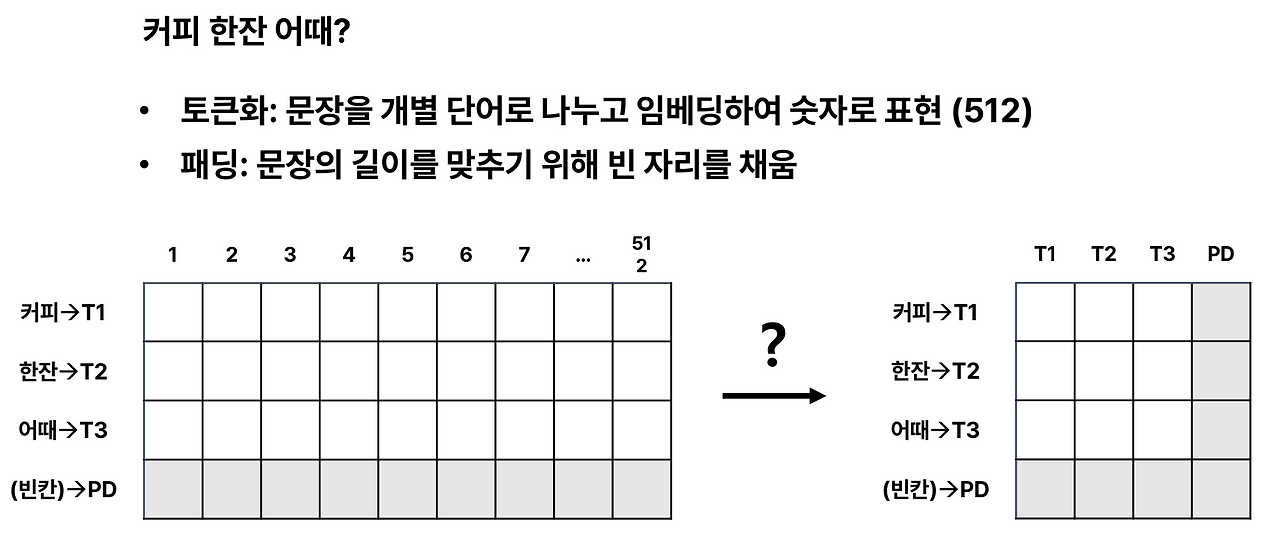

### Attention의 아이디어
- 한 단어를 처리할 때 문장의 다른 위치에 있는 단어들을 직접 확인
- 문장 안의 모든 토큰이 서로를 바라보며 관계를 계산할 수 있음

1. 단어는 숫자 벡터가 됨
    - 문장 > Token > Token ID > Embedding Layer > Embedding Vector
    - 예) 커피 / 한잔 / 어때 (문장을 3개의 토큰으로 나누었다고 가정)
        - 커피: 0
        - 한잔: 1
        - 어때: 2
    - 위 숫자는 단어의 의미를 나타내는 숫자가 아니라 단어를 구별하기 위한 번호
    - Token ID를 nn.Embedding에 넣으면 각 토큰이 여러 개의 실수로 이루어진 Embedding Vector로 변환
    - Attention의 원리를 쉽게 확인하기 위해 4차원만 사용

In [2]:
import torch
import torch.nn as nn

torch.manual_seed(2026)

token = ['lets', 'get', 'coffee']
token_ids = torch.tensor([0, 1, 2])  # 보통 auto tokenizing 씀
print('토큰: ', token)
print('토큰 ID: ', token_ids)
print('토큰 ID Shape: ', token_ids.shape)

토큰:  ['lets', 'get', 'coffee']
토큰 ID:  tensor([0, 1, 2])
토큰 ID Shape:  torch.Size([3])


### 2. Token ID와 Embedding
- 커피:0 에서 0은 단지 커피를 찾기 위한 번호
- 실제 Embedding Parameter는 보통 양수, 음수, 소수를 포함하는 ***연속적인 실수값*** 가짐
- Embedding(3, 4): 3개의 토큰 각각에 대해 4차원 벡터를 저장하는 학습 가능한 표 (가중치의 모양 > (3, 4))
- 각 행은 하나의 Token ID에 대응(0번 행: 커피, 1번 행: 한잔, 2번 행: 어때)
- 처음 만들어진 값은 학습이 끝난 의미 있는 임베딩이 아님(파라미터를 초기화한 값)
- 모델이 학습하면 역전파와 Optimizer에 의해 값들이 계속 업데이트됨

In [3]:
# num_embeddings: 사용할 수 있는 토큰 ID의 개수
# embedding_dim: 하나의 토큰을 숫자로 표현
embedding = nn.Embedding(num_embeddings=3, embedding_dim=4)
print(embedding)
print(embedding.weight)

Embedding(3, 4)
Parameter containing:
tensor([[ 0.3655,  1.9065,  0.2169,  0.2963],
        [-1.0160, -0.6064,  0.1744, -0.6306],
        [-0.0954,  0.3191, -1.4710,  0.2610]], requires_grad=True)


In [4]:
X = embedding(token_ids)
print("Embedding Result X: \n", X)
print("Shape: ", X.shape)
print("Token Count: ", X.shape[0])
print("Embedding Dim: ", X.shape[1])

Embedding Result X: 
 tensor([[ 0.3655,  1.9065,  0.2169,  0.2963],
        [-1.0160, -0.6064,  0.1744, -0.6306],
        [-0.0954,  0.3191, -1.4710,  0.2610]], grad_fn=<EmbeddingBackward0>)
Shape:  torch.Size([3, 4])
Token Count:  3
Embedding Dim:  4


### Self-Attention
- 셀프 어텐션(Self-Attention)에서는 입력 임베딩을 이용해 단어들 사이의 관계를 수치적으로 계산합니다. 
- 먼저 각 단어의 임베딩 벡터를 복사하여 두 개의 행렬을 만들고, 하나는 그대로 두고 다른 하나는 전치(transpose)하여 행과 열을 바꿉니다. 
- 이렇게 준비된 두 행렬을 곱하면 각 단어가 다른 단어와 얼마나 관련이 있는지를 나타내는 유사도 행렬이 만들어집니다. 
- 예를 들어 “귤, 과, 사과”라는 문장에서 ‘사과’ 벡터와 ‘귤’ 벡터의 내적을 통해 두 단어의 관련성을 계산하고, 이를 W1​ 같은 값으로 저장합니다. 
- 이 행렬은 결국 모델이 어떤 단어를 더 주목해야 할지를 결정하는 근거가 됩니다.
- 즉, 셀프 어텐션은 행렬 곱 연산을 통해 모든 단어 쌍의 관계를 한 번에 계산하고, 이를 토대로 문맥을 더 깊이 이해하게 만드는 핵심 메커니즘입니다.

- 같은 문장 안에서 서로의 단어를 바라봄
- 예) 커피<>커피, 커피<>한잔, 커피<>어때 의 토큰과 관계를 계산
- 토큰이 3개라면 관계 점수는 3*3 형태가 됨

### 2. Token ID와 Embedding
- 커피:0 에서 0은 단지 커피를 찾기 위한 번호
- 실제 Embedding Parameter는 보통 양수, 음수, 소수를 포함하는 ***연속적인 실수값*** 가짐
- Embedding(3, 4): 3개의 토큰 각각에 대해 4차원 벡터를 저장하는 학습 가능한 표 (가중치의 모양 > (3, 4))
- 각 행은 하나의 Token ID에 대응(0번 행: 커피, 1번 행: 한잔, 2번 행: 어때)
- 처음 만들어진 값은 학습이 끝난 의미 있는 임베딩이 아님(파라미터를 초기화한 값)
- 모델이 학습하면 역전파와 Optimizer에 의해 값들이 계속 업데이트됨

### Query, Key, Value
- Query(Q): 지금 내가 무엇을 찾고 있는가?
    - Q = XW_Q
- Key(K): 내가 가진 정보의 특징
    - K = XW_K
- Value(V): 실제로 가져올 정보
    - V = XW_V

In [5]:
embed_dim = 4
W_Q = nn.Linear(embed_dim, embed_dim, bias=False)
W_K = nn.Linear(embed_dim, embed_dim, bias=False)
W_V = nn.Linear(embed_dim, embed_dim, bias=False)

Q = W_Q(X)
K = W_K(X)
V = W_V(X)

print("X: ", X.shape)
print("Q: ", Q.shape)
print("K: ", K.shape)
print("V: ", V.shape)

print("Q = ", Q)
print("K = ", K)
print("V = ", V)

X:  torch.Size([3, 4])
Q:  torch.Size([3, 4])
K:  torch.Size([3, 4])
V:  torch.Size([3, 4])
Q =  tensor([[-0.3668, -0.8192,  0.1926, -0.0615],
        [ 0.0741,  0.5607, -0.4887, -0.2062],
        [-0.7271, -0.7872,  0.5736,  0.0966]], grad_fn=<MmBackward0>)
K =  tensor([[ 0.2404, -0.5815,  0.5650, -0.2048],
        [-0.4260,  0.1304, -0.2097,  0.2134],
        [ 0.6014, -0.1235,  0.1331,  0.7654]], grad_fn=<MmBackward0>)
V =  tensor([[ 0.1731,  0.7597, -0.1451,  0.0721],
        [-0.0511,  0.2425,  0.5725, -0.4278],
        [-0.2781, -0.3329, -0.1504,  0.5977]], grad_fn=<MmBackward0>)


- 현재 단어의 'Query'와 다른 단어들의 'Key'를 비교하면 현재 단어가 다른 단어와 얼마나 관련 있는지 나타내는 점수를 만들 수 있음
- 벡터끼리 비교할 때 내적을 사용
- Q @ K.T > Q:(3, 4), K(3, 4) > Q:(3, 4), K.T(4, 3) > 결과: (3, 3)

> 모든 토큰과 모든 토큰 사이의 관계 점수표가 만들어짐

In [6]:
scores = Q @ K.T
print("Q Shape: ", Q.shape)
print("K.T Shape: ", K.T.shape)
print("scores shape: ", scores.shape)
print("scores: \n", scores)  # 아직 학습되지 않았기 때문에 의미는 없음

Q Shape:  torch.Size([3, 4])
K.T Shape:  torch.Size([4, 3])
scores shape:  torch.Size([3, 3])
scores: 
 tensor([[ 0.5096, -0.0041, -0.1408],
        [-0.5422,  0.1000, -0.2476],
        [ 0.5872,  0.1074, -0.1898]], grad_fn=<MmBackward0>)


- Query로 검색하고 > Key와 비교해서 관련도를 구하고 > 관련도가 높은 데이터의 Value를 가져옴
- 중요한 점은 Transformer에서는 X를 그냥 세 번 복사하는 것이 아니라 서로 다른 학습 가능한 가중치 행렬 "W_Q", "W_K", "W_V"를 곱해 Q, K, V를 만듦

### Q와 K를 곱하는 이유
- 현재 단어의 'Query'와 다른 단어들의 'Key'를 비교하면 현재 단어가 다른 단어와 얼마나 관련 있는지 나타내는 점수를 만들 수 있음
- 점수 (Score 행렬)
    - 행(Row): 지금 보고 있는 토큰
    - 열(Column): 비교 대상 토큰
    - 예) [0, 2] 위치의 값은 "커피"의 Query와 "어때"의 Key의 관계 점수
    - 단순히 관련도를 나타내는 원시 점수 (raw score)

```
 tensor([[-0.0318,  0.1243,  0.0188],
        [ 0.0545,  0.2870,  0.1594],
        [ 0.1724, -0.0339, -0.0326]], grad_fn=<MmBackward0>)
```

In [7]:
for i, query_token in enumerate(token):
    print(f'[{query_token}]가 바라보는 점수')
    for j, key_token in enumerate(token):
        print(f' > {key_token:4s}: {scores[i, j].item():3f}')

[lets]가 바라보는 점수
 > lets: 0.509621
 > get : -0.004102
 > coffee: -0.140836
[get]가 바라보는 점수
 > lets: -0.542157
 > get : 0.100048
 > coffee: -0.247637
[coffee]가 바라보는 점수
 > lets: 0.587229
 > get : 0.107413
 > coffee: -0.189819


### Scaled Dot-Product(내적) Attention
- scaled_scores = scores / sqrt(d_k) 
    - d_k: key 벡터의 차원
- 벡터 차원이 커질수록 내적 결과도 커질 가능성이 높음
- 점수가 너무 커지면 Softmax 결과가 한쪽으로 지나치게 몰릴 수 있고 학습이 불안정해질 수 있음
    - Softmax: 점수를 0~1 사이의 값으로 변환하고, 전체 합이 1이 되도록 만드는 함수 >> 값들의 해석이 쉬워짐
    - 점수 간 차이가 클수록 가장 높은 점수에 가중치가 집중됨 >> Softmax Saturation (포화)
- 벡터 차원이 커져서 점수가 지나치게 커지는 것을 완화하기 위해 sqrt(d_k)로 나누어 Scaling
    - 한 토큰에 지나치게 집중되는 현상 완화

In [8]:
import math

d_k = K.size(-1)
scaled_socres = scores / math.sqrt(d_k)
print("d_k: ", d_k)
print("sqrt(d_k): ", math.sqrt(d_k))
print("scaled_socres: \n", scaled_socres)

d_k:  4
sqrt(d_k):  2.0
scaled_socres: 
 tensor([[ 0.2548, -0.0021, -0.0704],
        [-0.2711,  0.0500, -0.1238],
        [ 0.2936,  0.0537, -0.0949]], grad_fn=<DivBackward0>)


### Softmax 사용
- Softmax를 사용하면 각 행의 값이 0~1사이의 값이 되고, 한 행의 합이 1이 됨
- 예) [0.2, 0.6, 0.2]
    - 첫 번째 토큰 정보 20%
    - 두 번째 토큰 정보 60%
    - 세 번째 토큰 정보 20%

> 정확히 말하면 확률 모델의 정답 확률이라기보다, Value를 얼마나 섞을지 정하는 가중치를 뜻함

In [9]:
attention_weights = torch.softmax(scaled_socres, dim=-1)
print("Attention Weights")
print(attention_weights)
print()
print("각 행의 합")
print(attention_weights.sum(dim=-1))

Attention Weights
tensor([[0.4007, 0.3099, 0.2894],
        [0.2827, 0.3897, 0.3276],
        [0.4057, 0.3192, 0.2751]], grad_fn=<SoftmaxBackward0>)

각 행의 합
tensor([1., 1., 1.], grad_fn=<SumBackward1>)


### Value
- 실제로 가져올 정보
- Attention Weight @ V
- 예) '커피'의 가중치가 커피 0.2 / 한잔 0.5 / 어때 0.3
    - 새로운 '커피' 벡터는 개념적으로 ```커피의 V*0.2 + 한잔의 V*0.5 + 어때의 V*0.4```
- 다른 단어의 정보를 중요도에 따라 섞어서 새로운 문맥 벡터를 만드는 것

In [10]:
output = attention_weights @ V
print("V shape: ", V.shape)
print("attention_weights shape: ", attention_weights.shape)
print("Output shape: ", output.shape)
print(output)

V shape:  torch.Size([3, 4])
attention_weights shape:  torch.Size([3, 3])
Output shape:  torch.Size([3, 4])
tensor([[-0.0270,  0.2832,  0.0757,  0.0693],
        [-0.0621,  0.2002,  0.1328,  0.0494],
        [-0.0226,  0.2940,  0.0825,  0.0571]], grad_fn=<MmBackward0>)


### 전체 흐름
1. 입력 임베딩
2. Q, K, V 생성
3. 관련도 계산 (QK.T)
4. 값의 크기 조정
5. softmax: 각 단어를 얼마나 볼 것인지 Attention Weight 생성
6. Value를 가중합

> 각 토큰은 자기 자신만의 정보가 아니라 주변 토큰의 문맥이 반영된 새로운 벡터

In [11]:
def scaled_dot_product_attention(Q, K, V, mask=None):
    # 1. Key 벡터의 차원
    d_k = Q.size(-1)

    # 2. Q와 K의 내적으로 관계 점수 계산
    scores = Q @ K.transpose(-2, -1)

    # 3. 차원의 제곱근으로 나누어 점수 크기 조절
    scores = scores / math.sqrt(d_k)

    # 4. 필요하면 Mask 적용
    if mask is not None:
        scores = scores.masked_fill(mask == 0, float("-inf"))

    # 5. Softmax를 이용해 Attention Weight 계산
    weights = torch.softmax(scores, dim=-1)

    # 6. Attention Weight를 이용해 Value를 가중합
    output = weights @ V

    return output, weights


attention_output, weights = scaled_dot_product_attention(Q, K, V)

print("Attention Output:")
print(attention_output)

print("\nAttention Weights:")
print(weights)

Attention Output:
tensor([[-0.0270,  0.2832,  0.0757,  0.0693],
        [-0.0621,  0.2002,  0.1328,  0.0494],
        [-0.0226,  0.2940,  0.0825,  0.0571]], grad_fn=<MmBackward0>)

Attention Weights:
tensor([[0.4007, 0.3099, 0.2894],
        [0.2827, 0.3897, 0.3276],
        [0.4057, 0.3192, 0.2751]], grad_fn=<SoftmaxBackward0>)


### Padding Mask
- 실제 학습에서는 문장 길이가 서로 다름
    - 예) "커피 한잔 어때", "오늘 날씨가 정말 좋아", "안녕하세요"
- 배치 처리를 위해 짧은 문장 뒤에 "\<PAD\>"를 붙여 길이를 맞출 수 있음
- PAD는 실제 의미가 없는 토큰
- Attention은 PAD를 참고하지 못하도록 Mask를 적용
    - Mask된 위치의 Attention Score를 매우 작은 값(-inf)으로 바꾸면 Softmax 이후 그 위치의 가중치는 사실상 0이 됨

In [12]:
sample_scores = torch.tensor([[2.0, 1.0, 0.5, 3.0]])
padding_mask = torch.tensor([1, 1, 1, 0])
masked_scores = sample_scores.masked_fill(padding_mask==0, float("-inf"))
weights_before = torch.softmax(sample_scores, dim=-1)
weights_after = torch.softmax(masked_scores, dim=-1)

print("Mask 전: ", weights_before)
print("Mask 후: ", weights_after)

Mask 전:  tensor([[0.2321, 0.0854, 0.0518, 0.6308]])
Mask 후:  tensor([[0.6285, 0.2312, 0.1402, 0.0000]])


# 4. Multi-Head Attention
- Self-Attention을 한 번만 수행하면 하나의 관점에서 관계를 학습
- Transformer에서는 이를 여러 개의 Head로 나누어 동시에 Attention을 수행
- 예) Head는 학습 결과에 따라 
    - 가까운 단어 관계
    - 문법적 관계
    - 의미적 관계
    - 특정 위치 관계 등
- 512차원 임베딩을 64차원씩 잘라서 각각 Attention하는 방법 (하나의 예)
    - embed_dim = 512
    - num_heads = 8
    - 각 Head가 처리하는 차원: head_dim = 512 / 8 = 64
    - Head가 Attention을 계산한 뒤 결과들을 다시 이어 붙이고, 마지막 출력 선형 변환을 적용

In [13]:
embed_dim = 8
num_heads = 2
head_dim = embed_dim // num_heads
print('전체 임베딩 차원: ', embed_dim)
print('Head의 개수: ', num_heads)
print('Head 하나의 차원: ', head_dim)

# batch=1, token=3, embed_dim=8
x = torch.randn(1, 3, embed_dim)
print('입력 shape: ', x.shape)

전체 임베딩 차원:  8
Head의 개수:  2
Head 하나의 차원:  4
입력 shape:  torch.Size([1, 3, 8])


In [14]:
mha = nn.MultiheadAttention(embed_dim=8, num_heads=2, batch_first=True)
attn_output, attn_weights = mha(query=x, key=x, value=x, need_weights=True)
print('입력 shape: ', x.shape)
print('출력 shape: ', attn_output.shape)
print('Attention Weight shape: ', attn_weights.shape)
print(attn_weights)

입력 shape:  torch.Size([1, 3, 8])
출력 shape:  torch.Size([1, 3, 8])
Attention Weight shape:  torch.Size([1, 3, 3])


tensor([[[0.3454, 0.3520, 0.3026],
         [0.3598, 0.3557, 0.2845],
         [0.3378, 0.3401, 0.3221]]], grad_fn=<MeanBackward1>)


### Head별 Attentnion Weight
- 기본 설정에서는 여러 Head의 Attention Weight가 평균되어 반환
- average_attn_weights=False로 지정하면 각 Head의 결과를 따로 확인할 수 있음
- 출력 shape: (batch, num_heads, harget_length, source_length)

In [15]:
attn_output, head_weights = mha(query=x, key=x, value=x, need_weights=True, average_attn_weights=False)

print('Head별 Attention Weight shape: ')
print(attn_weights.shape)
# batch=1, 3x3이 2개

print('Head 0: \n', head_weights[0, 0])
print('Head 1: \n', head_weights[0, 1])

Head별 Attention Weight shape: 
torch.Size([1, 3, 3])
Head 0: 
 tensor([[0.3521, 0.3527, 0.2953],
        [0.3333, 0.4230, 0.2437],
        [0.3633, 0.3807, 0.2560]], grad_fn=<SelectBackward0>)
Head 1: 
 tensor([[0.3387, 0.3514, 0.3100],
        [0.3863, 0.2884, 0.3253],
        [0.3123, 0.2995, 0.3881]], grad_fn=<SelectBackward0>)


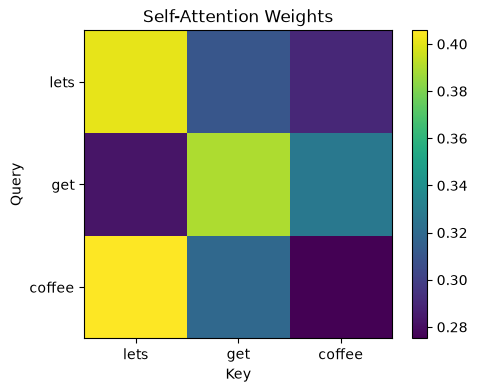

In [16]:
import matplotlib.pyplot as plt

# 밝거나 큰 값을 가진 위치일수록 해당 Query가 해당 key를 더 많이 참고한다는 뜻
weights_np = weights.detach().numpy()

plt.figure(figsize=(5, 4))
plt.imshow(weights_np)
plt.xticks(range(len(token)), token)
plt.yticks(range(len(token)), token)
plt.xlabel("Key")
plt.ylabel("Query")
plt.title("Self-Attention Weights")
plt.colorbar()
plt.show()

# 5. Transformer
- 트랜스포머(Transformer)는 2017년 [구글 논문(Attention is all you need)](https://arxiv.org/pdf/1706.03762)에서 발표된 자연어 처리(NLP)와 다양한 시퀀스 학습 문제에서 뛰어난 성능을 보이는 신경망 아키텍처로, 어텐션 메커니즘을 활용하여 병렬 연산이 가능하고 장기 의존성을 효과적으로 처리할 수 있습니다.
- 기존의 순환신경망(RNN)과 달리 순차적인 계산 없이 전체 입력 문장을 한 번에 처리하며, 특히 "셀프 어텐션(Self-Attention)"을 사용하여 문장 내 단어 간 관계를 동적으로 학습합니다. 대표적인 트랜스포머 기반 모델로는 BERT, GPT, T5 등이 있으며, 머신 번역, 텍스트 생성, 문서 요약 등 다양한 AI 분야에서 널리 활용되고 있습니다.

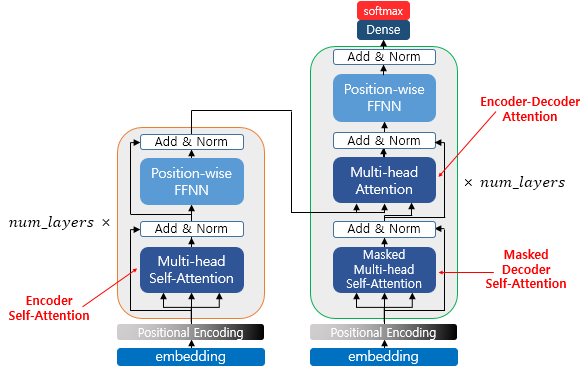

### Encoder
- 문장 > Tokenization > Token ID > Embedding > 위치 정보 추가 (Positional Encoding) > Multi-Head Self-Attention > Residual + LayerNorm > Encoder 출력

#### 1. Token ID 만들기
- tokenizer가 문자열을 토큰으로 나누고 정수 ID로 바꿈

In [17]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(2026)
torch.set_printoptions(precision=3, sci_mode=False)

vocab = {"<PAD>":0, "커피":1, "한잔":2, "어때":3}
tokens = ["커피", "한잔", "어때"]
token_ids = torch.tensor([[1, 2, 3]])

print(tokens)
print(token_ids)
print("shape:", token_ids.shape)

['커피', '한잔', '어때']
tensor([[1, 2, 3]])
shape: torch.Size([1, 3])


#### 2. Token ID > Embedding
- 정수 ID를 nn.Embedding에 넣어 학습 가능한 실수 벡터로 바꿈
    - 커피 > 1 > [8개의 실수]
    - 한잔 > 2 > [8개의 실수]
    - 어때 > 3 > [8개의 실수]

In [18]:
vocab_size = len(vocab)
d_model = 8

embedding = nn.Embedding(vocab_size, d_model, padding_idx=0)
X = embedding(token_ids)

print(X)
print("shape:", X.shape)  # (batch, sequence_length, d_model)

tensor([[[-0.545,  0.219, -1.496,  0.343, -0.192, -0.903,  0.998,  0.036],
         [ 0.244,  0.073,  0.900, -0.805, -0.531,  1.579,  1.451, -1.079],
         [-2.191,  1.543, -0.777,  2.194,  0.926,  0.685, -0.603,  0.600]]],
       grad_fn=<EmbeddingBackward0>)
shape: torch.Size([1, 3, 8])


#### 3. Positional Encoding
- Self-Attention은 토큰 사이 관계를 계산하지만, recurrent 구조처럼 입력 순서를 따라 한 칸씩 처리하지 않음
- 모델에 각 토큰의 위치 정보를 제공해야할 필요가 있음
- 원래 Transformer 논문은 Sin/Cos 기반 Positional Encoding을 사용했음
- Transformer 입력 = Token Embedding + Positional Encoding
    - Transformer가 합쳐진 숫자 하나하나를 보고 단어 값 또는 위치 값을 구분하는 것은 아님
    - 두 정보가 같은 d_model 차원의 벡터에 의도적으로 섞어서 하나의 입력 표현으로 만드는 것
- 각 위치에 서로 다른 Sin/Cos 패턴을 만들어 임베딩에 더함 > 여러 주기의 신호를 함께 사ㅏ용하므로 위치마다 다른 패턴을 얻음

```
Token Embedding E = [단어를 표현하는 숫자들]
Position P = [현재 위치를 표현하는 Sin/Cos 패턴]
입력 X = E + P

커피 = [0.20, -0.40, 0.70, ...]
0번 위치의 Position = [0.00, 1.00, 0.00, ...]
최종 입력 [0.20, 0.60, 0.70, ...]
```

> 예를 들어 "나는 너를 좋아해"와 "너는 나를 좋아해"는 비슷한 단어가 등장하지만 위치와 문법적 역할이 달라 의미도 달라짐

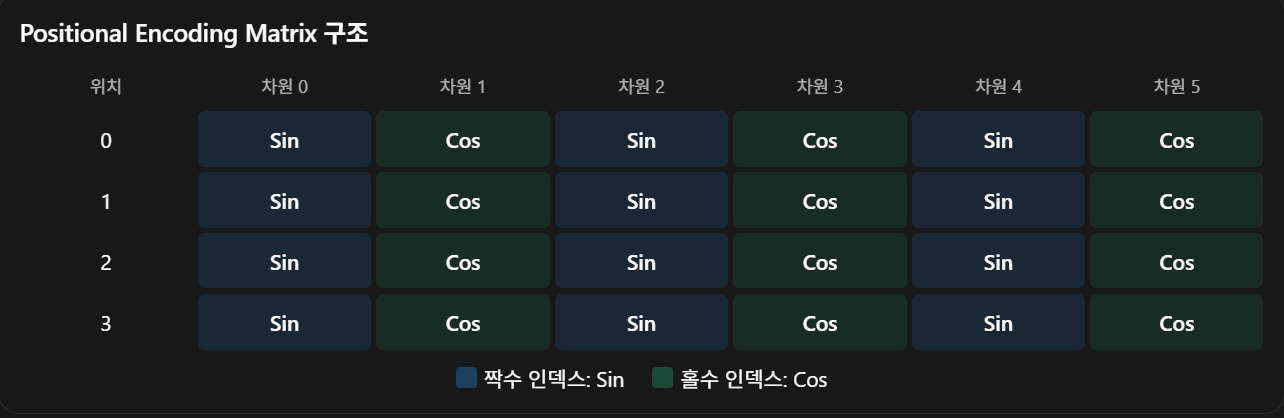

In [19]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=100):
        super().__init__()

        # 0부터 max_len-1까지 위치 인덱스를 생성하고, (max_len, 1) 형태의 2차원 Tensor로 변환
        position = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)  

        # 각 원소에 e^x를 적용하여 Sin/Cos의 주파수 계수를 계산
        div_term = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float32)
            * (-math.log(10000.0) / d_model)
        )

        # 각 토큰의 위치 정보를 저장할 (max_len, d_model) 크기의 0으로 채워진 Tensor 생성
        pe = torch.zeros(max_len, d_model)

        # 모든 위치의 짝수 인덱스 차원(0, 2, 4, ...)에 Sin 값 저장
        pe[:, 0::2] = torch.sin(position * div_term)

        # 모든 위치의 홀수 인덱스 차원(1, 3, 5, ...)에 Cos 값 저장
        pe[:, 1::2] = torch.cos(position * div_term)

        # Positional Encoding에 Batch 차원을 추가하고 (1, max_len, d_model),
        # 학습 중 업데이트되지 않는 Buffer로 모델에 등록
        # 학습 파라미터가 아닌 고정 텐서이므로 buffer로 등록
        # pe는 공식으로 미리 계산해 놓은 고정값
        self.register_buffer("pe", pe.unsqueeze(0))

    # 순전파
    def forward(self, x):
        # 입력 Tensor에서 현재 문장의 길이(Sequence Length)를 가져옴
        seq_len = x.size(1)

        # 현재 문장 길이만큼 Positional Encoding을 선택하여 Token Embedding에 더함
        return x + self.pe[:, :seq_len]

pos_encoding = PositionalEncoding(d_model)  # 현재 d_model = 8
X_pos = pos_encoding(X)

print("Embedding:", X.shape)
print("Position 추가:", X_pos.shape)
print(X_pos)

Embedding: torch.Size([1, 3, 8])
Position 추가: torch.Size([1, 3, 8])
tensor([[[-0.545,  1.219, -1.496,  1.343, -0.192,  0.097,  0.998,  1.036],
         [ 1.085,  0.614,  1.000,  0.190, -0.521,  2.579,  1.452, -0.079],
         [-1.282,  1.127, -0.578,  3.174,  0.946,  1.685, -0.601,  1.600]]],
       grad_fn=<AddBackward0>)


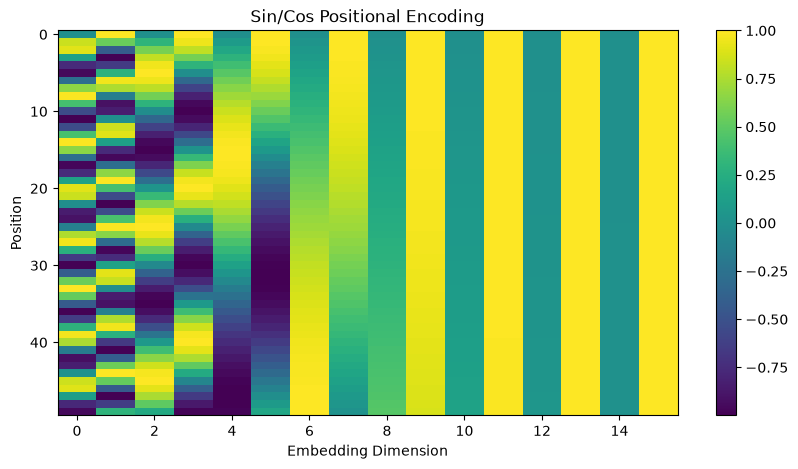

In [20]:
# 아래 코드는 바로 앞 Markdown 셀의 개념을 실제 텐서와 shape로 확인하는 실습입니다.
import matplotlib.pyplot as plt

pe_demo = PositionalEncoding(d_model=16, max_len=50)
values = pe_demo.pe[0].detach().numpy()

plt.figure(figsize=(10, 5))
plt.imshow(values, aspect="auto")
plt.xlabel("Embedding Dimension")
plt.ylabel("Position")
plt.title("Sin/Cos Positional Encoding")
plt.colorbar()
plt.show()

### 4. Multii-Head Self-Attention

In [21]:
# Multi-Head Attention에서 사용할 Head 개수를 2개로 설정
num_heads = 2

# Multi-Head Attention Layer 생성
mha = nn.MultiheadAttention(
    embed_dim=d_model,      # 입력 Token Embedding의 차원
    num_heads=num_heads,    # Attention Head 개수
    batch_first=True        # 입력 Shape: (Batch, Sequence, Embedding)
)

# Q, K, V에 동일한 X_pos를 전달하여 Multi-Head Self-Attention 수행
attn_out, attn_weights = mha(
    query=X_pos,                # Query: 다른 토큰과의 관계를 찾는 벡터
    key=X_pos,                  # Key: Query와 비교하여 Attention Score 계산
    value=X_pos,                # Value: Attention Weight를 적용할 정보
    need_weights=True,          # Attention Weight도 함께 반환
    average_attn_weights=False  # Head별 Weight를 평균 내지 않고 개별 반환
)

print("입력:", X_pos.shape)
print("출력:", attn_out.shape)
print("Head별 Weight:", attn_weights.shape)

입력: torch.Size([1, 3, 8])
출력: torch.Size([1, 3, 8])
Head별 Weight: torch.Size([1, 2, 3, 3])


### 5. Residual Connection
- Attention 결과에 원래 입력을 다시 더함 >> Residual/Skip Connection
- y = x + F(x)
- 원래 정보(x)를 유지한 채 새로 계산한 정보(F(x))를 보태는 형태
- 기존 내용 위에 수정/보완본을 더해서 전달한는 것
- 역전파에서 학습 신호가 복잡한 Attention/FFN 경로만 통하지 않고 더 직접적으로 이전 층까지 갈 수 있는 길이 더 생기는 것
- 깊은 모델에 최적화를 돕는 Connection

In [22]:
residual = X_pos + attn_out
print(residual.shape)

torch.Size([1, 3, 8])


In [23]:
x_original = X_pos[0, 0]
attention_change = attn_out[0, 0]
x_after_residual = x_original + attention_change

print("원래 입력 x        :", x_original)
print("Attention 결과 F(x):", attention_change)
print("Residual x + F(x)  :", x_after_residual)

# shape가 같아야 원소별 덧셈이 가능합니다.
print("x shape    :", x_original.shape)
print("F(x) shape :", attention_change.shape)

원래 입력 x        : tensor([-0.545,  1.219, -1.496,  1.343, -0.192,  0.097,  0.998,  1.036],
       grad_fn=<SelectBackward0>)
Attention 결과 F(x): tensor([-0.497, -0.147,  0.130,  0.086, -0.147, -0.007, -0.149,  0.629],
       grad_fn=<SelectBackward0>)
Residual x + F(x)  : tensor([-1.042,  1.072, -1.365,  1.429, -0.339,  0.090,  0.849,  1.665],
       grad_fn=<AddBackward0>)
x shape    : torch.Size([8])
F(x) shape : torch.Size([8])


### 6. Layer Normalization
- 각 토큰의 feature 축(embedded 된 vector 값들)을 기준으로 정규화
- Residual에서 원래 정보 + 새 정보를 합친 뒤 값의 분포가 지나치게 흔들리지 않도록 정돈
- 한 개의 입력 샘플 내부의 모든 뉴런 값에 대해 평균과 분산을 계산하여 정규화하는 방식입니다. 
- 즉, 각 배치(토큰)의 크기와 무관하게 특징(feature) 차원별로 정규화하므로, 시퀀스 길이가 달라져도 안정적으로 작동한다.

In [24]:
norm1 = nn.LayerNorm(d_model)
x1 = norm1(residual)

print("전:", residual[0,0])
print("후:", x1[0,0])
print("평균:", x1[0,0].mean())
print("분산:", x1[0,0].var(unbiased=False))

전: tensor([-1.042,  1.072, -1.365,  1.429, -0.339,  0.090,  0.849,  1.665],
       grad_fn=<SelectBackward0>)
후: tensor([-1.256,  0.730, -1.560,  1.066, -0.595, -0.193,  0.520,  1.288],
       grad_fn=<SelectBackward0>)
평균: tensor(0.000, grad_fn=<MeanBackward0>)
분산: tensor(1.000, grad_fn=<VarBackward0>)


### 7. Feed Forward Network(FFN)
- Attention: 토큰들이 서로 정보를 주고받음
- FFN: 정보를 받은 각 토큰 벡터를 개별적으로 비선형 변환
- 논문에서 512 > 2048 > 512로 차원 변화
- Attention만 하면 다른 토큰에서 어떤 정보를 가져올지는 계산할 수 있지만, 가져온 정보를 각 토큰 안에서 충분히 비선형적으로 가공하는 단계가 필요
- 모든 위치에 같은 작은 신경망을 독립적으로 적용

In [25]:
ffn = nn.Sequential(
    nn.Linear(d_model, 32),  # 8 > 32
    nn.ReLU(),               # 비선형
    nn.Linear(32, d_model)   # 32 > 8
)

ffn_out = ffn(x1)
print("입력:", x1.shape)
print("출력:", ffn_out.shape)

입력: torch.Size([1, 3, 8])
출력: torch.Size([1, 3, 8])


### 두 번째 Residual도 같은 원리
- 첫 번째 Residual은 Attention이 만든 변화량을 원래 값에 더하고, 두 번째 Residual은 FFN이 만든 변화량을 FFN 입력에 더함
- 한 Encoder Block 안에 보통 Attention용 Residual 1개 + FFN용 Residual 1개

In [26]:
norm2 = nn.LayerNorm(d_model)
encoder_output = norm2(x1 + ffn_out)
print(encoder_output)
print(encoder_output.shape)

tensor([[[-1.192,  0.787, -1.456,  1.027, -1.070,  0.099,  0.867,  0.937],
         [-0.302, -0.276, -0.002, -0.457, -1.390,  2.246,  0.652, -0.471],
         [-1.626,  0.182, -0.915,  1.775, -0.432,  0.766, -0.389,  0.638]]],
       grad_fn=<NativeLayerNormBackward0>)
torch.Size([1, 3, 8])


### 8. Padding Mask
- 배치 안의 문장 길이를 맞추기 위해 \<PAD\>를 넣음
```
커피 한잔 어때
커피 어때 <PAD>
```
- \<PAD\>는 의미가 없음. Attention에서 참고하지 않아야 함
- 문장 길이를 맞추려고 넣은 PAD는 실제 문장 내용이 아님. 이를 가리지 않으면 Attention이 PAD에도 가중치를 줄 수 있어 의미 없는 정보를 참고하게 됨

In [27]:
padded_ids = torch.tensor([
    [1, 2, 3],
    [1, 3, 0]
])

padding_mask = padded_ids.eq(0)  # 0과 같은 값만 padding_mask

print(padded_ids)
print(padding_mask)
# False = 실제 토큰
# True  = PAD

tensor([[1, 2, 3],
        [1, 3, 0]])
tensor([[False, False, False],
        [False, False,  True]])


In [28]:
# Token ID를 Embedding으로 변환한 후 Positional Encoding 추가
padded_x = pos_encoding(embedding(padded_ids))

# PAD 토큰을 Key로 참조하지 않도록 Masking하여 Self-Attention 수행
masked_out, masked_weights = mha(
    padded_x, padded_x, padded_x,
    key_padding_mask=padding_mask,  # PAD 위치에 Attention을 주지 않도록 차단
    need_weights=True               # Attention Weight 반환
)

# Batch별 Attention Weight 출력 (Head 평균)
print(masked_weights)

# 두 번째 문장의 Attention Matrix 확인
print("\n두 번째 문장:")
print(masked_weights[1])

tensor([[[0.277, 0.322, 0.401],
         [0.377, 0.205, 0.418],
         [0.286, 0.299, 0.414]],

        [[0.392, 0.608, 0.000],
         [0.372, 0.628, 0.000],
         [0.414, 0.586, 0.000]]], grad_fn=<MeanBackward1>)

두 번째 문장:
tensor([[0.392, 0.608, 0.000],
        [0.372, 0.628, 0.000],
        [0.414, 0.586, 0.000]], grad_fn=<SelectBackward0>)


### Causal Mask (인과적 마스크)
- Padding Mask: 의미 없는 PAD를 차단   
- Casual Mask: 미래 토큰을 미리 보지 못하게 차단
    - 다음 토큰 생성에서는 현재 위치보다 뒤에 있는 정답을 미리 보면 안됨
```
         나는   커피를   마신다
나는      O       X       X 
커피를    O       O       X 
마신다    O       O       O 
```
- GPT 계열의 autoregressive 생성 원리를 이해할 때 매우 중요함
- 학습 때 정답 문장을 알고 있는데도 Mask가 필요한 이유?
    - 다음 토큰 예측 학습에서는 정답 시퀀스를 한꺼번에 넣어 병렬 계산할 수 있음
    - Mask가 없다면 앞 위치가 뒤쪽의 정답 토큰을 미리 볼 수 있어 문제가 너무 쉬워짐
    - 병렬 계산은 하되 각 위치가 과거/현재까지만 보도록 제한


In [34]:
seq_len = 4

# triu: 상삼각 부분만 남기는 함수
# 
# False = 볼 수 있음
# True = 미래이므로 차단
causal_mask = torch.triu(
    torch.ones(seq_len, seq_len, dtype=torch.bool),
    diagonal=1
)

print(causal_mask)

tensor([[False,  True,  True,  True],
        [False, False,  True,  True],
        [False, False, False,  True],
        [False, False, False, False]])


### 9. Encoder Block 직접 만들기

In [38]:

class SimpleTransformerEncoderBlock(nn.Module):
    def __init__(self, d_model=8, num_heads=2, d_ff=32, dropout=0.1):

        # 부모 클래스 nn.Module의 초기화 함수 실행
        # nn.Linear, nn.LayerNorm 같은 Layer들이 모델의 구성 요소로 올바르게 등록됨
        super().__init__()  

        # 1. Multi-Head Self-Attention
        # d_model: 각 토큰의 Embedding 차원 (8)
        # num_heads: Attention Head 개수 (2)
        # 각 Head는 8 / 2 = 4차원 사용
        # batch_first=True: 입력 형태 (batch, seq_len, d_model)
        self.self_attention = nn.MultiheadAttention(
            d_model,
            num_heads,
            dropout=dropout,
            batch_first=True
        )

        # --------------------------------------------------

        # 2. Layer Normalization
        # Attention 이후, FFN 이후 각각 정규화
        # 마지막 차원(d_model)을 기준으로 정규화
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)

        # --------------------------------------------------

        # 3. Feed Forward Network (FFN)
        # 각 토큰을 독립적으로 처리하는 신경망
        # 8차원 → 32차원 → 8차원
        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_ff),  # 8 → 32
            nn.ReLU(),                 # 비선형 활성화
            nn.Dropout(dropout),       # 과적합 방지
            nn.Linear(d_ff, d_model)   # 32 → 8
        )

        # --------------------------------------------------

        # 4. Dropout
        # Attention 및 FFN 출력에 각각 적용
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)

        # --------------------------------------------------

    def forward(self, x, padding_mask=None):

        # 5. Multi-Head Self-Attention
        # Q, K, V 모두 x를 사용 → Self-Attention
        # padding_mask=True인 Key 위치는 참조하지 않음
        # attn_out: (batch, seq_len, d_model)
        # weights: (batch, seq_len, seq_len)
        #          기본적으로 Head별 Weight를 평균
        attn_out, weights = self.self_attention(
            x, x, x,
            key_padding_mask=padding_mask,  # Padding 위치가 Attention에 사용되지 않도록 차단하는 설정
            need_weights=True
        )

        # --------------------------------------------------

        # 6. Residual Connection + LayerNorm
        # Attention Output에 Dropout 적용
        # 원래 입력 x와 Attention Output 더함
        # 정규화 Layer Normalization 적용
        x = self.norm1(x + self.dropout1(attn_out))

        # --------------------------------------------------

        # 7. Feed Forward Network
        # 각 토큰 벡터에 같은 FFN 적용
        # 토큰 간 Attention 없이 독립적으로 변환
        ffn_out = self.ffn(x)
        
        # --------------------------------------------------

        # 8. Residual Connection + LayerNorm
        # FFN의 출력에 Dropout 적용
        # FFN 입력 x와 FFN 출력을 더한 후 정규화
        x = self.norm2(x + self.dropout2(ffn_out))

        # 최종 Encoder 출력과 Attention Weight 반환
        return x, weights


# 9. Encoder Block 생성
# d_model = 8
# num_heads = 2
# d_ff = 32
# dropout = 0.1
block = SimpleTransformerEncoderBlock()  # __init__만 돌아감

# 10. Forward Pass 실행
# X_pos: Embedding + Positional Encoding 결과
out, weights = block(X_pos) 

print("입력:", X_pos.shape)
print("출력:", out.shape)
print("Weight:", weights.shape)


입력: torch.Size([1, 3, 8])
출력: torch.Size([1, 3, 8])
Weight: torch.Size([1, 3, 3])


### 10. Encoder와 Decoder

1. Encoder: 입력 토큰들의 관계를 Self-Attention으로 처리
2. Decoder: 출력 생성
    - Masked Self-Attention: 미래 출력 토큰을 보지 않음
    - Cross-Attention: Encoder의 출력 정보를 참고
```
Q: Decoder의 현재 표현
K: Encoder 출력
V: Encoder 출력
```
- Decoder가 현재 출력을 만들기 위해 입력 문장의 어디를 참고해야 하는가를 계산하는 과정

```
입력 > Encoder > 출력 > Masked Self-Attention > Cross-Attention > FFN > 출력
```


In [41]:
import torch
import torch.nn as nn

# 1. Cross-Attention Layer 생성
cross_attention = nn.MultiheadAttention(
    embed_dim=8,       # 각 토큰의 벡터 차원 (d_model=8)
    num_heads=2,       # Attention Head 2개 (각 Head는 4차원)
    batch_first=True   # (batch_size, seq_len, d_model)
)

# 2. Encoder 출력 생성 (예시 데이터)
# Batch: 1개, 입력 토큰: 5개, Embedding: 8차원
# 실제 모델에서는 Encoder를 통과한 출력이 들어옴
encoder_memory = torch.randn(1, 5, 8)

# 3. Decoder의 현재 Hidden State 생성 (예시 데이터)
# Batch: 1개, 출력 위치: 3개, Embedding: 8차원
# 실제 모델에서는 Decoder의 이전 Layer 출력이 들어옴
decoder_state = torch.randn(1, 3, 8)

# 4. Cross-Attention 실행
cross_out, cross_weights = cross_attention(
    query=decoder_state,   # Q: Decoder가 어떤 정보를 찾을지
    key=encoder_memory,    # K: Encoder의 어떤 위치가 관련 있는지
    value=encoder_memory   # V: Encoder에서 가져올 정보
)

# 5. 결과 확인
print("K/V(Encoder):", encoder_memory.shape)
print("Q(Decoder):", decoder_state.shape)
print("출력:", cross_out.shape)
print("Weight:", cross_weights.shape)

K/V(Encoder): torch.Size([1, 5, 8])
Q(Decoder): torch.Size([1, 3, 8])
출력: torch.Size([1, 3, 8])
Weight: torch.Size([1, 3, 5])


# 6. BERT, GPT, T5를 구조 관점에서 보기

- BERT 계열: Encoder 중심. 양방향 문맥 표현을 이용하는 이해 작업에 널리 사용되었음
- GPT 계열: Decoder 계열의 Causal Self-Attention을 사용하는 autoregressive 구조
    - 앞의 토큰으로 다음 토큰을 예측함
- T5 계열: Encoder-Decoder Transformer

> Transformer라고 해서 항상 Encoder와 Decoder 전체를 모두 사용하는 것은 아님